In [18]:
# =========================
# Cell 1 — Imports + generate data
# =========================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Optional but convenient (pairplot)
import seaborn as sns

from risk_dataset_generator import generate_company_risk_dataset

# Generate dataset
N = 1000
SEED = 7
OUTLIER_PROB = 0.0

# Full dataset (includes hidden columns) for QA
df = generate_company_risk_dataset(
    n=N,
    seed=SEED,
    outlier_prob=OUTLIER_PROB,
    return_all_columns=True,
)

df_students = generate_company_risk_dataset(
    n=N,
    seed=SEED,
    outlier_prob=OUTLIER_PROB,
    return_all_columns=False,
)

print(df.shape, df_students.shape)
df.head()


(1000, 20) (1000, 10)


,annual_revenue_eur,_profit_margin_raw,annual_costs_eur,size_score,audited,clients,top_client_share,market_focus,employees,ceo_tenure_years,cost_exposure,customer_concentration,profit_margin,sales_risk,cost_risk,sales_flag,cost_flag,y,risk [target],risk_score_external
0,3.760853e+06,-0.088075,4.227259e+06,0.525095,1,1264,0.454630,"[consumer_retail, manufacturing]",15,20.724814,1.000000,0.124713,-0.124016,0.668366,1.681842,0,1,2,cost_risk,55.632106
1,2.464004e+07,0.096795,2.106062e+07,0.797214,1,10000,0.085097,"[regulated, B2B_contracts]",27,7.327881,0.873015,0.000133,0.145268,0.480794,1.168906,0,0,0,healthy,40.848954
2,1.064283e+07,0.159619,8.945848e+06,0.675686,0,10000,0.130379,"[ads_marketplace, consumer_retail]",21,1.255069,0.911018,0.000311,0.159448,0.411704,1.368022,0,0,0,healthy,40.687382
3,2.374770e+05,0.222763,1.912800e+05,0.125207,0,465,0.204776,[regulated],1,16.613236,0.674924,0.034830,0.194533,0.851528,1.663299,0,1,2,cost_risk,72.836190
4,3.985647e+05,0.082993,3.743535e+05,0.200166,1,321,0.200896,[subscription],2,8.524731,0.243880,0.035510,0.060746,0.189561,0.682087,0,0,0,healthy,18.616709


In [19]:
# =========================
# Cell 2 — Column overview + missingness
# =========================
print("Columns:")
print(df.columns.tolist())

print("\nMissingness (top 20):")
na_rate = df.isna().mean().sort_values(ascending=False)
print(na_rate.head(20))

# Count invalid audited values (should exist due to outliers)
if "audited" in df.columns:
    audited_numeric = pd.to_numeric(df["audited"], errors="coerce")
    invalid_audited = (~audited_numeric.isin([0, 1])) & audited_numeric.notna()
    print("\nInvalid audited count:", int(invalid_audited.sum()))


Columns:
['annual_revenue_eur', '_profit_margin_raw', 'annual_costs_eur', 'size_score', 'audited', 'clients', 'top_client_share', 'market_focus', 'employees', 'ceo_tenure_years', 'cost_exposure', 'customer_concentration', 'profit_margin', 'sales_risk', 'cost_risk', 'sales_flag', 'cost_flag', 'y', 'risk [target]', 'risk_score_external']

Missingness (top 20):
annual_revenue_eur        0.0
_profit_margin_raw        0.0
annual_costs_eur          0.0
size_score                0.0
audited                   0.0
clients                   0.0
top_client_share          0.0
market_focus              0.0
employees                 0.0
ceo_tenure_years          0.0
cost_exposure             0.0
customer_concentration    0.0
profit_margin             0.0
sales_risk                0.0
cost_risk                 0.0
sales_flag                0.0
cost_flag                 0.0
y                         0.0
risk [target]             0.0
risk_score_external       0.0
dtype: float64

Invalid audited count: 

In [20]:
# =========================
# Cell 3 — Summary statistics: mean, std, min/max (numeric columns)
# =========================
num_cols = df.select_dtypes(include=[np.number]).columns
summary = pd.DataFrame({
    "mean": df[num_cols].mean(numeric_only=True),
    "std": df[num_cols].std(numeric_only=True),
    "min": df[num_cols].min(numeric_only=True),
    "p01": df[num_cols].quantile(0.01),
    "p50": df[num_cols].quantile(0.50),
    "p99": df[num_cols].quantile(0.99),
    "max": df[num_cols].max(numeric_only=True),
}).sort_index()
summary

,mean,std,min,p01,p50,p99,max
_profit_margin_raw,9.815340e-02,1.198566e-01,-0.233635,-0.171765,9.305203e-02,3.500000e-01,3.500000e-01
annual_costs_eur,6.397759e+06,1.025036e+07,35838.837335,46028.736925,1.389948e+06,4.202570e+07,5.210143e+07
annual_revenue_eur,7.018802e+06,1.107795e+07,51266.093557,55210.811804,1.538561e+06,4.671392e+07,4.979391e+07
audited,3.050000e-01,4.606378e-01,0.000000,0.000000,0.000000e+00,1.000000e+00,1.000000e+00
ceo_tenure_years,1.239342e+01,7.113031e+00,0.002784,0.366151,1.233369e+01,2.478103e+01,2.499413e+01
clients,4.803111e+03,4.001945e+03,56.000000,131.830000,3.279500e+03,1.000000e+04,1.000000e+04
cost_exposure,6.824954e-01,2.330943e-01,0.106186,0.206413,7.035457e-01,1.000000e+00,1.000000e+00
cost_flag,3.970000e-01,4.895208e-01,0.000000,0.000000,0.000000e+00,1.000000e+00,1.000000e+00
cost_risk,1.341235e+00,3.786512e-01,0.181844,0.421141,1.348068e+00,2.094160e+00,2.533697e+00
customer_concentration,2.613146e-02,4.637996e-02,0.000046,0.000046,6.398347e-03,2.170553e-01,3.798216e-01


risk [target]
both_risks    181
cost_risk     216
healthy       543
sales_risk     60
Name: count, dtype: int64


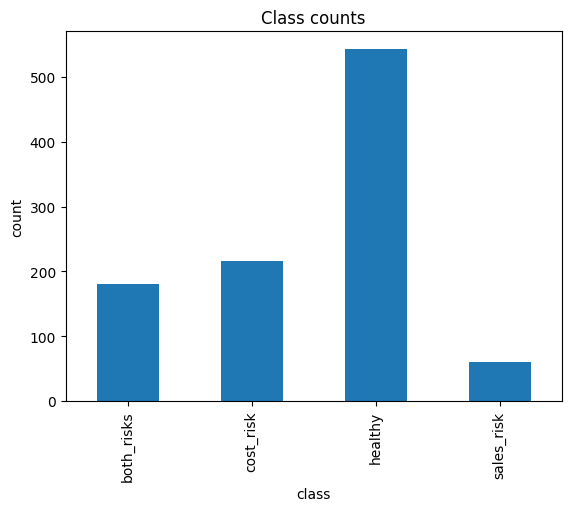

In [21]:
# =========================
# Cell 4 — Class balance (y)
# =========================
class_counts = df["risk [target]"].value_counts().sort_index()

print(class_counts)

plt.figure()
class_counts.plot(kind="bar")
plt.title("Class counts")
plt.xlabel("class")
plt.ylabel("count")
plt.show()

In [22]:
# % Healthy / Sales risk / Cost risk
# (both_risks counts towards both Sales and Cost)

import pandas as pd

# Make sure the mapping exists (skip if you already created it)
df["risk"] = df["y"].map({0: "healthy", 1: "sales_risk", 2: "cost_risk", 3: "both_risks"})

n = len(df)

pct_healthy = (df["risk"] == "healthy").mean() * 100
pct_sales_any = df["risk"].isin(["sales_risk", "both_risks"]).mean() * 100
pct_cost_any  = df["risk"].isin(["cost_risk", "both_risks"]).mean() * 100

summary = pd.DataFrame({
    "group": ["healthy", "sales_risk (incl. both)", "cost_risk (incl. both)"],
    "count": [
        int((df["risk"] == "healthy").sum()),
        int(df["risk"].isin(["sales_risk", "both_risks"]).sum()),
        int(df["risk"].isin(["cost_risk", "both_risks"]).sum()),
    ],
    "percentage": [pct_healthy, pct_sales_any, pct_cost_any],
})

display(summary)

print("\nFull class breakdown (y):")
display(df["risk"].value_counts(normalize=True).mul(100).round(2).rename("percentage").to_frame())


,group,count,percentage
0,healthy,543,54.3
1,sales_risk (incl. both),241,24.1
2,cost_risk (incl. both),397,39.7



Full class breakdown (y):


,percentage
risk,
healthy,54.3
cost_risk,21.6
both_risks,18.1
sales_risk,6.0


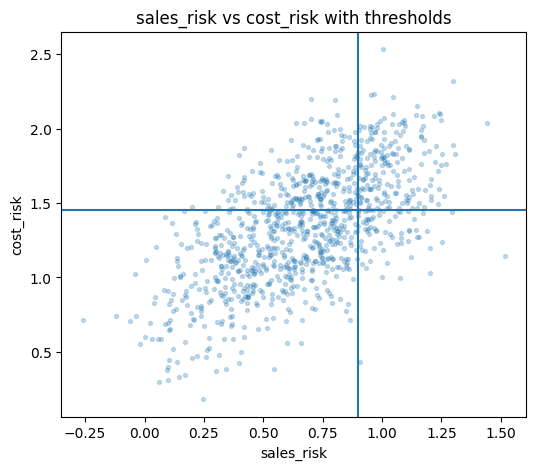

Healthy (%): 54.300000000000004
Below sales threshold (%): 75.9
Below cost threshold (%): 60.3


In [37]:
import matplotlib.pyplot as plt
from risk_dataset_generator import Thresholds

ths = Thresholds()

plt.figure(figsize=(6,5))
plt.scatter(df["sales_risk"], df["cost_risk"], s=8, alpha=0.25)

plt.axvline(ths.t_sales)
plt.axhline(ths.t_cost)

plt.title("sales_risk vs cost_risk with thresholds")
plt.xlabel("sales_risk")
plt.ylabel("cost_risk")
plt.show()

print("Healthy (%):", 100*((df["sales_risk"] < ths.t_sales) & (df["cost_risk"] < ths.t_cost)).mean())
print("Below sales threshold (%):", 100*(df["sales_risk"] < ths.t_sales).mean())
print("Below cost threshold (%):", 100*(df["cost_risk"] < ths.t_cost).mean())

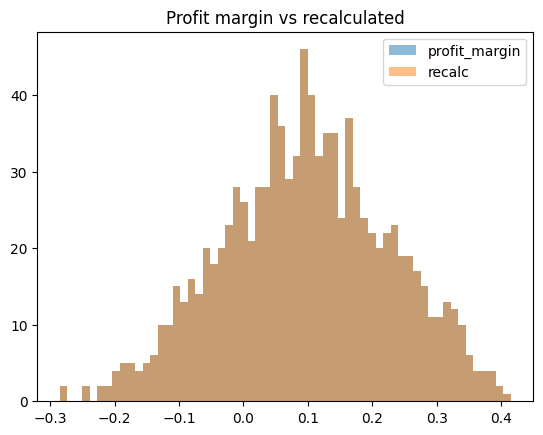

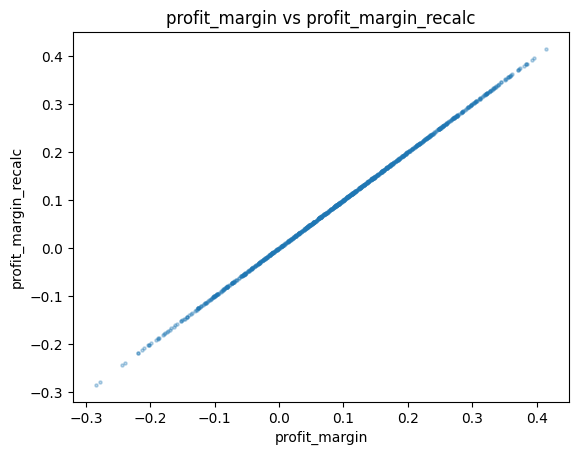

In [23]:
# =========================
# Cell 5 — Check derived margin (should match formula)
# =========================
df_check = df.copy()
df_check["profit_margin_recalc"] = (
    (df_check["annual_revenue_eur"] - df_check["annual_costs_eur"]) / df_check["annual_revenue_eur"].replace(0, np.nan)
)

plt.figure()
plt.hist(df_check["profit_margin"].dropna(), bins=60, alpha=0.5, label="profit_margin")
plt.hist(df_check["profit_margin_recalc"].dropna(), bins=60, alpha=0.5, label="recalc")
plt.title("Profit margin vs recalculated")
plt.legend()
plt.show()

# Scatter check
plt.figure()
plt.scatter(df_check["profit_margin"], df_check["profit_margin_recalc"], s=5, alpha=0.3)
plt.title("profit_margin vs profit_margin_recalc")
plt.xlabel("profit_margin")
plt.ylabel("profit_margin_recalc")
plt.show()

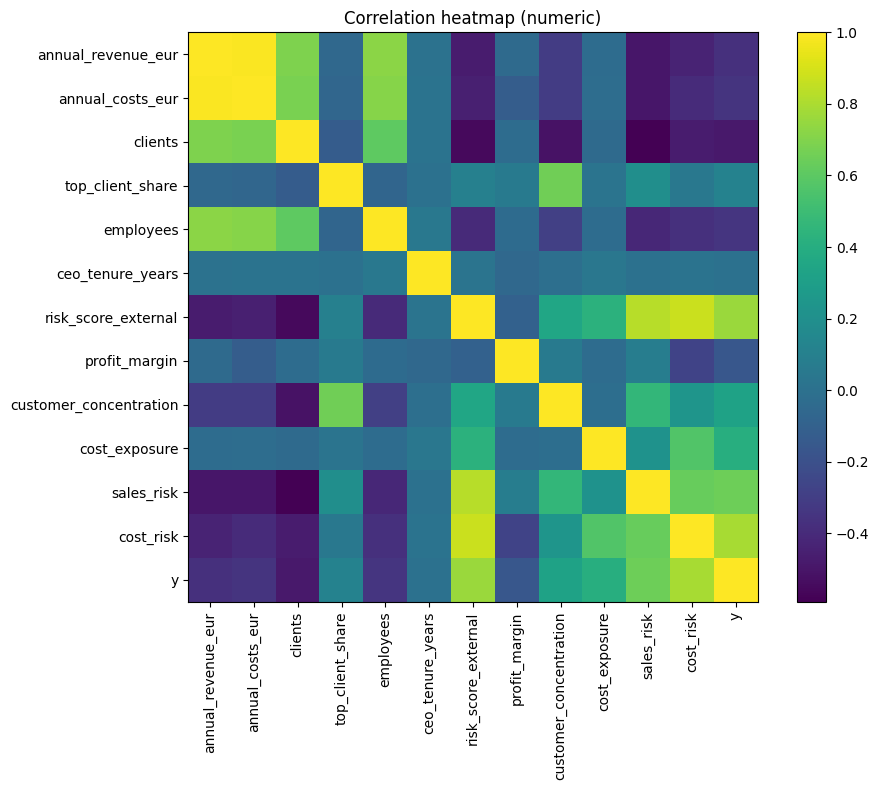

In [35]:
# =========================
# Cell 6 — Correlation heatmap (numeric features only)
# =========================
# Exclude target for this plot, include it separately later
corr_cols = [
    "annual_revenue_eur",
    "annual_costs_eur",
    "clients",
    "top_client_share",
    "employees",
    "ceo_tenure_years",
    "risk_score_external",
    "profit_margin",
    "customer_concentration",
    "cost_exposure",
    "sales_risk",
    "cost_risk",
    "y",
]

corr_cols = [c for c in corr_cols if c in df.columns]

corr = df[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(10, 8))
plt.imshow(corr)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.index)), corr.index)
plt.title("Correlation heatmap (numeric)")
plt.colorbar()
plt.tight_layout()
plt.show()

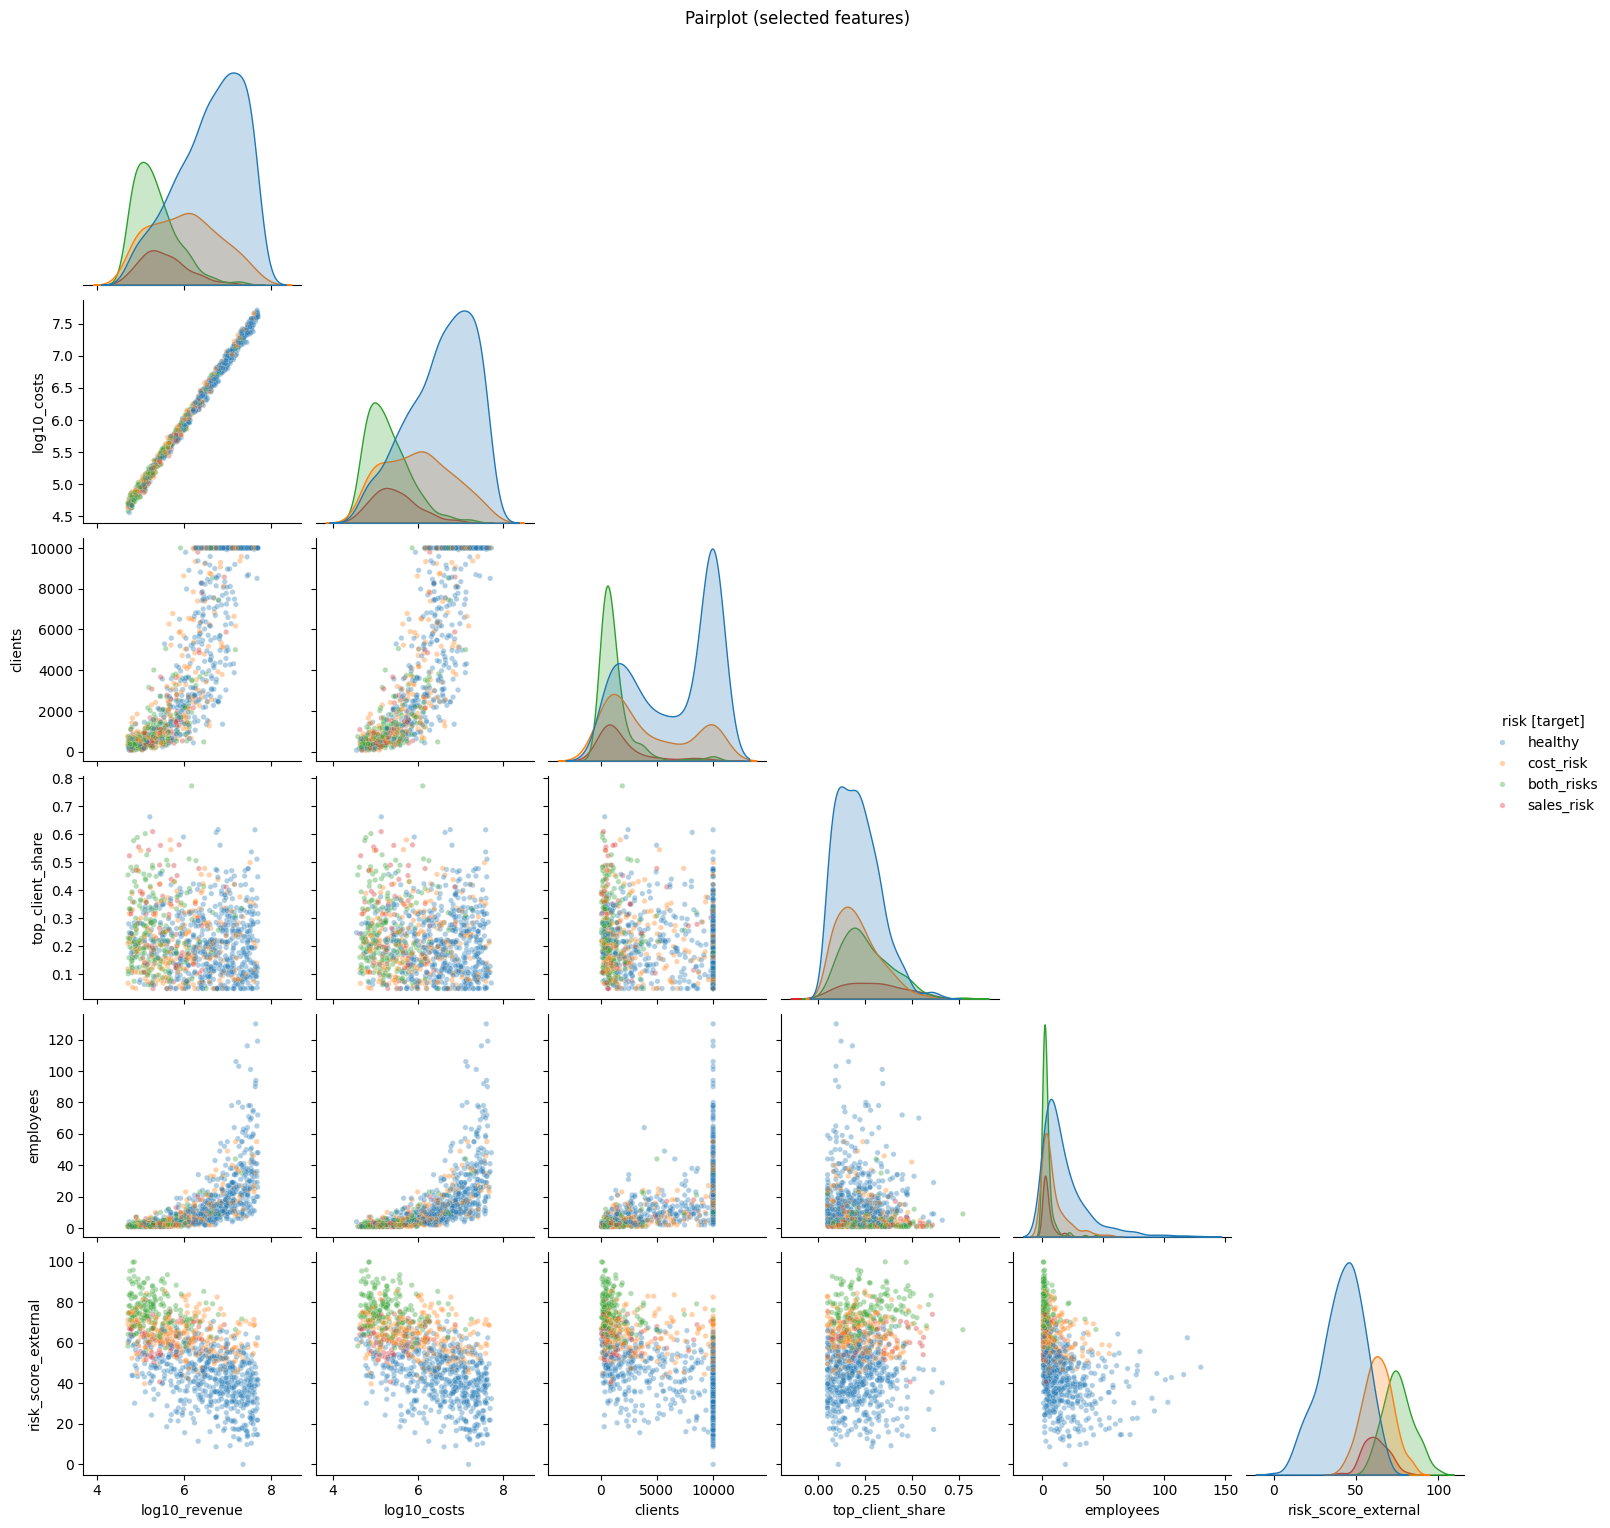

In [25]:
# =========================
# Cell 7 — Pairplot (selected visible features)
# =========================
# Pairplot can be slow; sample
plot_df = df_students.sample(n=min(2000, len(df_students)), random_state=SEED).copy()
# labels = {0: "healthy", 1: "sales_risk", 2: "cost_risk", 3: "both"}
# plot_df["y_label"] = plot_df["y"].map(labels)

# Use log10 revenue/cost to reduce scale dominance
plot_df["log10_revenue"] = np.log10(plot_df["annual_revenue_eur"].clip(lower=1))
plot_df["log10_costs"] = np.log10(plot_df["annual_costs_eur"].clip(lower=1))

sns.pairplot(
    plot_df,
    vars=["log10_revenue", "log10_costs", "clients", "top_client_share", "employees", "risk_score_external"],
    hue="risk [target]",
    corner=True,
    plot_kws={"alpha": 0.35, "s": 15},
)
plt.suptitle("Pairplot (selected features)", y=1.02)
plt.show()

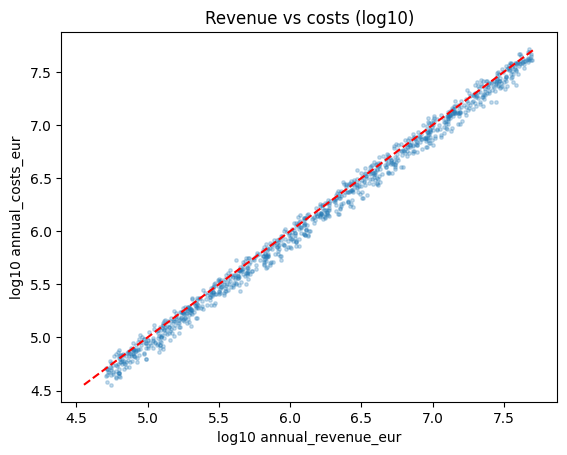

Corr(log10(rev), log10(costs)): 0.9973655168468061


In [26]:
# =========================
# Cell 8 — Revenue vs Costs scatter (should be strongly correlated)
# =========================
plt.figure()
plt.scatter(
    np.log10(df["annual_revenue_eur"].clip(lower=1)),
    np.log10(df["annual_costs_eur"].clip(lower=1)),
    s=6,
    alpha=0.25,
)
# Add identity line
max_val = max(
    np.log10(df["annual_revenue_eur"].clip(lower=1)).max(),
    np.log10(df["annual_costs_eur"].clip(lower=1)).max(),
)
min_val = min(
    np.log10(df["annual_revenue_eur"].clip(lower=1)).min(),
    np.log10(df["annual_costs_eur"].clip(lower=1)).min(),
)
plt.plot([min_val, max_val], [min_val, max_val], color="red", linestyle="--", label="y=x")

plt.title("Revenue vs costs (log10)")
plt.xlabel("log10 annual_revenue_eur")
plt.ylabel("log10 annual_costs_eur")
plt.show()

# Correlation value
print("Corr(log10(rev), log10(costs)):",
      np.corrcoef(np.log10(df["annual_revenue_eur"].clip(lower=1)), np.log10(df["annual_costs_eur"].clip(lower=1)))[0, 1])


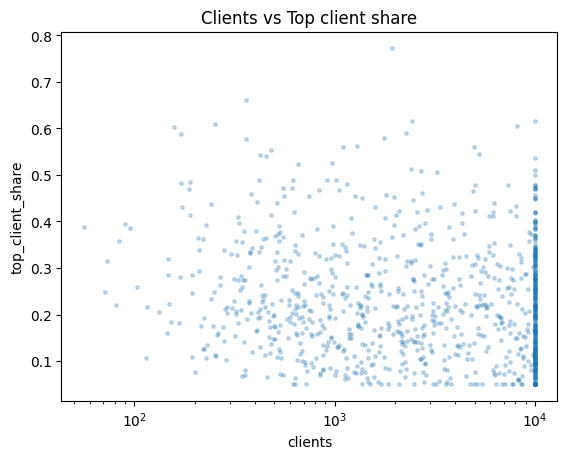

In [27]:
# =========================
# Cell 9 — Clients vs top client share (should be inverse-ish)
# =========================
plt.figure()
plt.scatter(
    df["clients"],
    df["top_client_share"],
    s=6,
    alpha=0.25,
)
plt.title("Clients vs Top client share")
plt.xlabel("clients")
plt.ylabel("top_client_share")
plt.xscale("log")
plt.show()

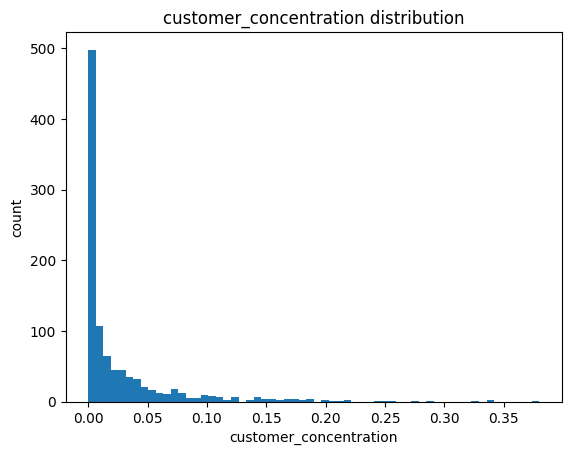

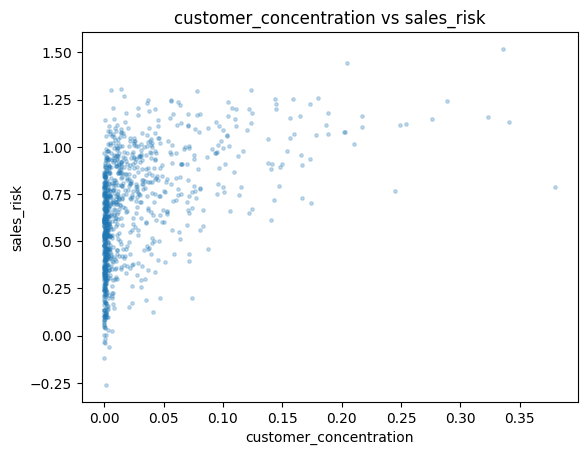

In [28]:
# =========================
# Cell 10 — Customer concentration distribution + relation to sales_risk
# =========================
plt.figure()
plt.hist(df["customer_concentration"].dropna(), bins=60)
plt.title("customer_concentration distribution")
plt.xlabel("customer_concentration")
plt.ylabel("count")
plt.show()

plt.figure()
plt.scatter(df["customer_concentration"], df["sales_risk"], s=6, alpha=0.25)
plt.title("customer_concentration vs sales_risk")
plt.xlabel("customer_concentration")
plt.ylabel("sales_risk")
plt.show()

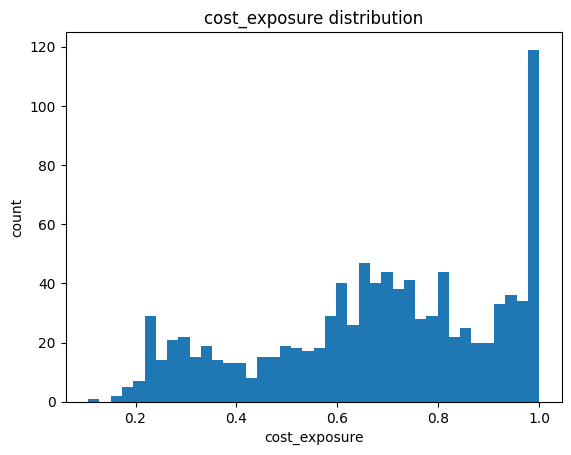

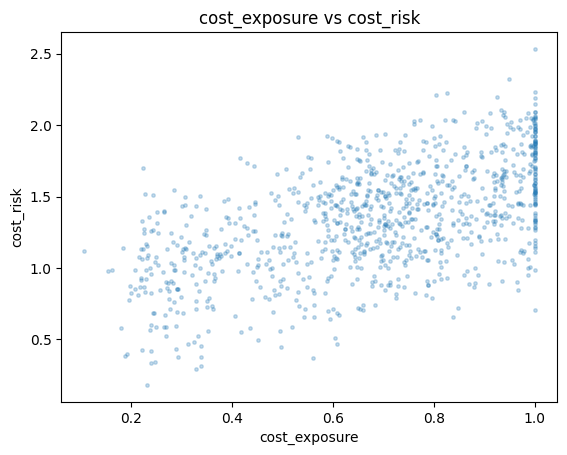

In [29]:
# =========================
# Cell 11 — Cost exposure distribution + relation to cost_risk
# =========================
plt.figure()
plt.hist(df["cost_exposure"].dropna(), bins=40)
plt.title("cost_exposure distribution")
plt.xlabel("cost_exposure")
plt.ylabel("count")
plt.show()

plt.figure()
plt.scatter(df["cost_exposure"], df["cost_risk"], s=6, alpha=0.25)
plt.title("cost_exposure vs cost_risk")
plt.xlabel("cost_exposure")
plt.ylabel("cost_risk")
plt.show()

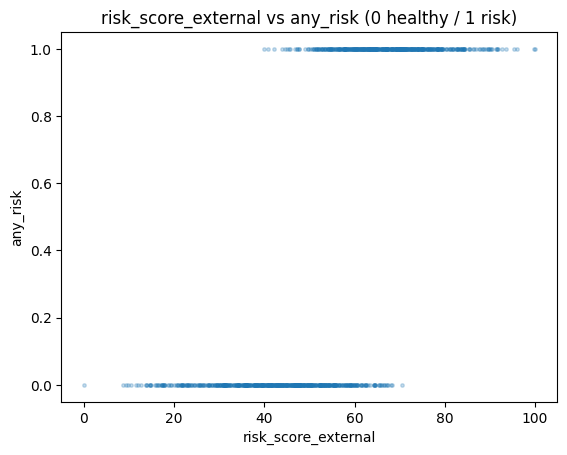

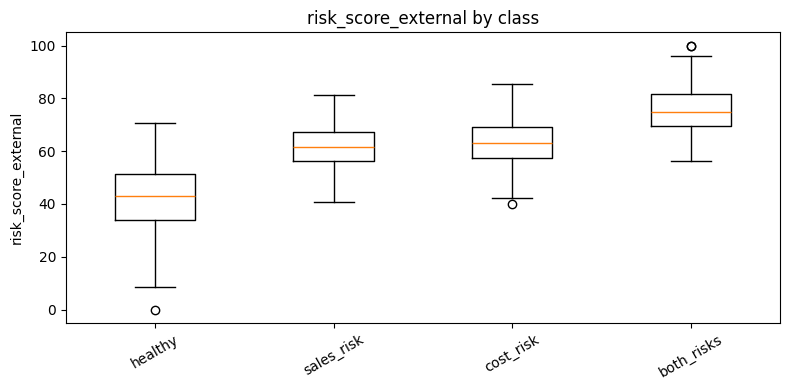

In [30]:
# =========================
# Cell 12 — External risk score: strong for risk/no-risk, weak for class type
# =========================
# Risk/no-risk vs external
risk_any = (df["y"] != 0).astype(int)
labels = {0: "healthy", 1: "sales_risk", 2: "cost_risk", 3: "both_risks"}

plt.figure()
plt.scatter(df["risk_score_external"], risk_any, s=6, alpha=0.25)
plt.title("risk_score_external vs any_risk (0 healthy / 1 risk)")
plt.xlabel("risk_score_external")
plt.ylabel("any_risk")
plt.show()

# Boxplot by class
plt.figure(figsize=(8, 4))
class_order = [0, 1, 2, 3]
data = [df.loc[df["y"] == c, "risk_score_external"].dropna() for c in class_order]
plt.boxplot(data, tick_labels=[labels[c] for c in class_order])
plt.title("risk_score_external by class")
plt.ylabel("risk_score_external")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


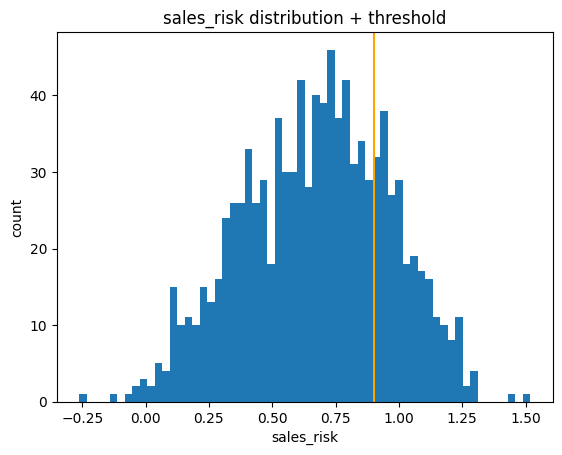

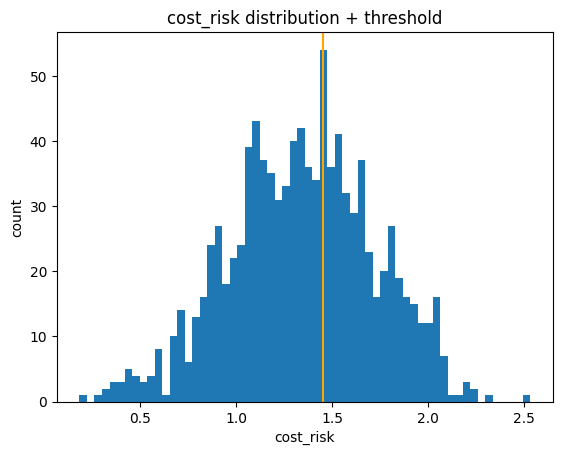

cost_flag,0,1
sales_flag,,
0,543,216
1,60,181


In [31]:
# =========================
# Cell 13 — Threshold checks (risk indexes and flags)
# =========================
# Visualize sales_risk and cost_risk histograms with thresholds
from risk_dataset_generator import Thresholds
ths = Thresholds()

plt.figure()
plt.hist(df["sales_risk"].dropna(), bins=60)
plt.axvline(ths.t_sales, color="orange")
plt.title("sales_risk distribution + threshold")
plt.xlabel("sales_risk")
plt.ylabel("count")
plt.show()

plt.figure()
plt.hist(df["cost_risk"].dropna(), bins=60)
plt.axvline(ths.t_cost, color="orange")
plt.title("cost_risk distribution + threshold")
plt.xlabel("cost_risk")
plt.ylabel("count")
plt.show()

# Confusion-like counts from flags
flag_table = pd.crosstab(df["sales_flag"], df["cost_flag"], rownames=["sales_flag"], colnames=["cost_flag"])
flag_table

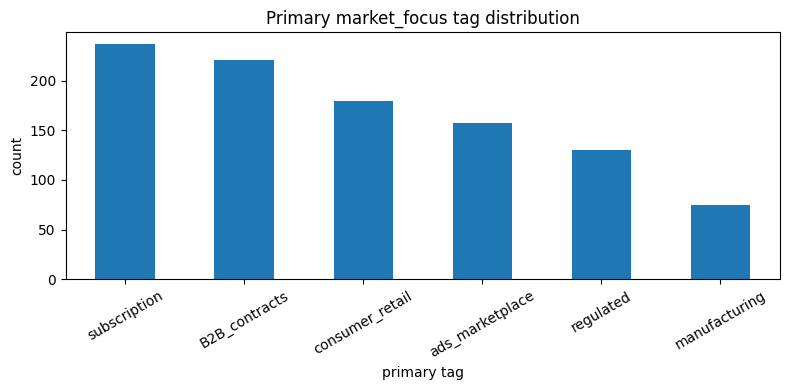

,tag,share,mean_cost_exposure,mean_cost_risk
1,subscription,0.346,0.454865,1.148739
5,B2B_contracts,0.324,0.772302,1.423573
4,consumer_retail,0.302,0.813416,1.468267
3,ads_marketplace,0.280,0.713915,1.360493
2,regulated,0.263,0.743182,1.396749
0,manufacturing,0.189,0.928484,1.588466


In [32]:
# =========================
# Cell 14 — Market focus sanity checks
# =========================
# Distribution of primary tag (first tag)
primary = df_students["market_focus"].apply(lambda x: x[0] if isinstance(x, list) and len(x) else "(missing)")

plt.figure(figsize=(8, 4))
primary.value_counts().plot(kind="bar")
plt.title("Primary market_focus tag distribution")
plt.xlabel("primary tag")
plt.ylabel("count")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Average cost_exposure by presence of tags
def has_tag(tag):
    return df["market_focus"].apply(lambda tags: isinstance(tags, list) and (tag in tags))

rows = []
for tag in ["manufacturing", "subscription", "regulated", "ads_marketplace", "consumer_retail", "B2B_contracts"]:
    m = has_tag(tag)
    rows.append({
        "tag": tag,
        "share": float(m.mean()),
        "mean_cost_exposure": float(df.loc[m, "cost_exposure"].mean()),
        "mean_cost_risk": float(df.loc[m, "cost_risk"].mean()),
    })

pd.DataFrame(rows).sort_values("share", ascending=False)

In [33]:
# =========================
# Cell 15 — Outlier inspection
# =========================
# Simple rules to spot corruption
outlier_rules = pd.DataFrame({
    "rev_too_big": df["annual_revenue_eur"] > 5e7,
    "costs_weird": (df["annual_costs_eur"] > 2.5 * df["annual_revenue_eur"]) | (df["annual_costs_eur"] < 0.05 * df["annual_revenue_eur"]),
    "audited_bad": ~pd.to_numeric(df["audited"], errors="coerce").isin([0, 1]) | df["audited"].isna(),
    "clients_bad": (pd.to_numeric(df["clients"], errors="coerce") <= 0) | df["clients"].isna(),
    "top_share_bad": (df["top_client_share"] < 0) | (df["top_client_share"] > 1) | df["top_client_share"].isna(),
})

print("Outlier counts:")
print(outlier_rules.sum().sort_values(ascending=False))

# Show some outlier rows
outlier_any = outlier_rules.any(axis=1)
df.loc[outlier_any].head(20)

Outlier counts:
rev_too_big      0
costs_weird      0
audited_bad      0
clients_bad      0
top_share_bad    0
dtype: int64


,annual_revenue_eur,_profit_margin_raw,annual_costs_eur,size_score,audited,clients,top_client_share,market_focus,employees,ceo_tenure_years,...,customer_concentration,profit_margin,sales_risk,cost_risk,sales_flag,cost_flag,y,risk [target],risk_score_external,risk


In [34]:
# =========================
# Cell 16 — Final: student view preview
# =========================
df_students.head(10)

,annual_revenue_eur,annual_costs_eur,audited,clients,top_client_share,market_focus,employees,ceo_tenure_years,risk_score_external,risk [target]
0,3.760853e+06,4.227259e+06,1,1264,0.454630,"[consumer_retail, manufacturing]",15,20.724814,55.632106,cost_risk
1,2.464004e+07,2.106062e+07,1,10000,0.085097,"[regulated, B2B_contracts]",27,7.327881,40.848954,healthy
2,1.064283e+07,8.945848e+06,0,10000,0.130379,"[ads_marketplace, consumer_retail]",21,1.255069,40.687382,healthy
3,2.374770e+05,1.912800e+05,0,465,0.204776,[regulated],1,16.613236,72.836190,cost_risk
4,3.985647e+05,3.743535e+05,1,321,0.200896,[subscription],2,8.524731,18.616709,healthy
5,2.092475e+07,1.775275e+07,0,10000,0.335402,"[B2B_contracts, manufacturing]",35,8.253708,71.750676,both_risks
6,5.197517e+04,4.998005e+04,0,540,0.230484,[ads_marketplace],1,17.886315,64.206759,both_risks
7,1.457757e+07,1.292961e+07,1,9190,0.254926,[subscription],14,10.287377,17.329734,healthy
8,1.233696e+07,1.020852e+07,1,10000,0.126580,"[B2B_contracts, ads_marketplace]",29,6.920974,31.239534,healthy
9,1.270003e+06,9.207718e+05,0,3623,0.080303,[B2B_contracts],8,21.524769,59.989732,healthy
